In [1]:
import glob, os, subprocess, shutil
os.environ["MACHINE_NAME"] = "kaggle-malak"
CODE = os.path.dirname(glob.glob("/kaggle/input/**/extract_faces.py", recursive=True)[0])
CELEB = os.path.dirname(glob.glob("/kaggle/input/**/List_of_testing_videos.txt", recursive=True)[0])
print(CODE, CELEB, sep="\n")
!pip install -q batch-face==1.5.4
!nvidia-smi --query-gpu=name --format=csv,noheader

/kaggle/input/datasets/malakkhaled202300369/nic-datasets/nic_code
/kaggle/input/datasets/malakkhaled202300369/nic-datasets/celebdf_test/celebdf_test
Tesla T4
Tesla T4


In [2]:
for v in glob.glob("/kaggle/input/**/c23/videos", recursive=True):
    name = v.split("/")[-3]
    if name == "youtube":
        dst = "/tmp/ffpp/original_sequences/youtube/c23/videos"
    else:
        dst = "/tmp/ffpp/manipulated_sequences/" + name + "/c23/videos"
    os.makedirs(os.path.dirname(dst), exist_ok=True)
    if not os.path.exists(dst):
        os.symlink(v, dst)

folders = glob.glob("/tmp/ffpp/original_sequences/youtube/c23/videos") + glob.glob("/tmp/ffpp/manipulated_sequences/*/c23/videos")
for d in sorted(folders):
    print(d, len(glob.glob(d + "/*.mp4")))

/tmp/ffpp/manipulated_sequences/Deepfakes/c23/videos 1000
/tmp/ffpp/manipulated_sequences/Face2Face/c23/videos 1000
/tmp/ffpp/manipulated_sequences/FaceSwap/c23/videos 1000
/tmp/ffpp/manipulated_sequences/NeuralTextures/c23/videos 1000
/tmp/ffpp/original_sequences/youtube/c23/videos 1000


In [3]:
LIMIT = 0
for split in ["train", "val", "test"]:
    !python {CODE}/extract_faces.py --dataset ffpp --root /tmp/ffpp --out /tmp/faces --split {split} --splits_dir {CODE} --limit {LIMIT}
!python {CODE}/extract_faces.py --dataset celebdf --root {CELEB} --out /tmp/faces --limit {LIMIT}

Downloading: "https://github.com/elliottzheng/face-detection/releases/download/0.0.1/Resnet50_Final.pth" to /root/.cache/torch/hub/checkpoints/Resnet50_Final.pth
100%|████████████████████████████████████████| 104M/104M [00:02<00:00, 43.3MB/s]
ffpp train: 3600 videos, 0 already done, 3600 to process, device cuda:0, detector resnet50
ffpp train: 100%|███████████████████████████| 3600/3600 [49:58<00:00,  1.20it/s]
done 3600, skipped 0, failed 0, videos in manifest 3600, crops 46076, 50.0 min
ffpp val: 700 videos, 0 already done, 700 to process, device cuda:0, detector resnet50
ffpp val: 100%|███████████████████████████████| 700/700 [16:58<00:00,  1.45s/it]
done 700, skipped 0, failed 0, videos in manifest 700, crops 22396, 17.0 min
ffpp test: 700 videos, 0 already done, 700 to process, device cuda:0, detector resnet50
ffpp test: 100%|██████████████████████████████| 700/700 [16:51<00:00,  1.45s/it]
done 700, skipped 0, failed 0, videos in manifest 700, crops 22400, 16.9 min
celebdf test: 5

ffpp/train videos 3600 crops 46076 failed 0
{0: 23039, 1: 23037}
ffpp/val videos 700 crops 22396 failed 0
{0: 4480, 1: 17916}
ffpp/test videos 700 crops 22400 failed 0
{0: 4480, 1: 17920}
celebdf/test videos 518 crops 16572 failed 0
{0: 5692, 1: 10880}


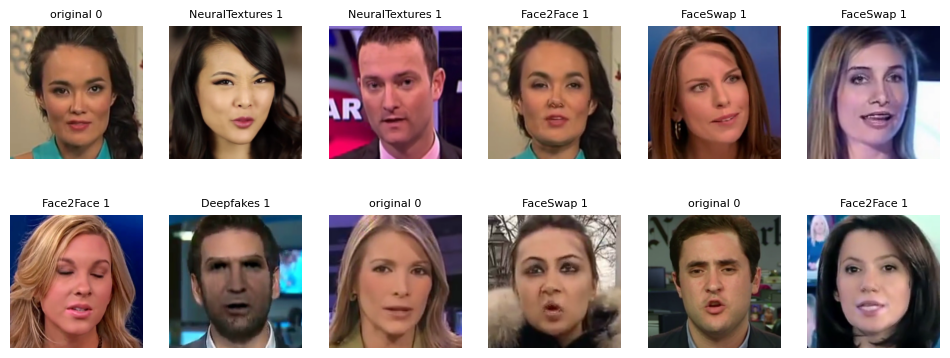

In [4]:
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

for part in ["ffpp/train", "ffpp/val", "ffpp/test", "celebdf/test"]:
    m = pd.read_csv("/tmp/faces/" + part + "/manifest.csv")
    f = pd.read_csv("/tmp/faces/" + part + "/failed_videos.csv")
    n_videos = m.groupby(["method", "video_id"]).ngroups
    print(part, "videos", n_videos, "crops", len(m), "failed", len(f))
    print(m.groupby("label").size().to_dict())

m = pd.read_csv("/tmp/faces/ffpp/val/manifest.csv")
sample = m.sample(12, random_state=0)
fig, axes = plt.subplots(2, 6, figsize=(12, 4.5))
for ax, (_, r) in zip(axes.ravel(), sample.iterrows()):
    ax.imshow(Image.open("/tmp/faces/" + r["path"]))
    ax.set_title(r["method"] + " " + str(r["label"]), fontsize=8)
    ax.axis("off")
plt.show()

In [5]:
os.makedirs("/kaggle/working/faces", exist_ok=True)
for part in ["ffpp/train", "ffpp/val", "ffpp/test", "celebdf/test"]:
    name = part.replace("/", "_")
    subprocess.run(["tar", "-cf", "/kaggle/working/faces/" + name + ".tar", "-C", "/tmp/faces", part], check=True)
    for f in ["manifest.csv", "failed_videos.csv", "runs.jsonl"]:
        shutil.copy("/tmp/faces/" + part + "/" + f, "/kaggle/working/faces/" + name + "_" + f)
!ls -lh /kaggle/working/faces

total 7.6G
-rw-r--r-- 1 root root   13 Oct 23 15:20 celebdf_test_failed_videos.csv
-rw-r--r-- 1 root root 2.4M Oct 23 15:20 celebdf_test_manifest.csv
-rw-r--r-- 1 root root  862 Oct 23 15:20 celebdf_test_runs.jsonl
-rw-r--r-- 1 root root 1.1G Oct 23 15:20 celebdf_test.tar
-rw-r--r-- 1 root root   13 Oct 23 15:20 ffpp_test_failed_videos.csv
-rw-r--r-- 1 root root 2.1M Oct 23 15:20 ffpp_test_manifest.csv
-rw-r--r-- 1 root root  784 Oct 23 15:20 ffpp_test_runs.jsonl
-rw-r--r-- 1 root root 1.6G Oct 23 15:20 ffpp_test.tar
-rw-r--r-- 1 root root   13 Oct 23 15:20 ffpp_train_failed_videos.csv
-rw-r--r-- 1 root root 4.1M Oct 23 15:20 ffpp_train_manifest.csv
-rw-r--r-- 1 root root  787 Oct 23 15:20 ffpp_train_runs.jsonl
-rw-r--r-- 1 root root 3.4G Oct 23 15:20 ffpp_train.tar
-rw-r--r-- 1 root root   13 Oct 23 15:20 ffpp_val_failed_videos.csv
-rw-r--r-- 1 root root 2.0M Oct 23 15:20 ffpp_val_manifest.csv
-rw-r--r-- 1 root root  783 Oct 23 15:20 ffpp_val_runs.jsonl
-rw-r--r-- 1 root root 1.6G Oct